In [ ]:
import sys
sys.path.append("../src")

from types import SimpleNamespace

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import properscoring as ps

from configs.load_config import load_config

from data_processing.load import (
    load_dataset,
    load_windpower,
    load_evaluation_forecast_data,
    load_scaler_params,
)

from data_processing.utils import (
    load_torch_model,
    load_checkpoint,
)

from models.build import build_model

from training.evaluate import (
    test_QR,
    test_BNN,
    evaluate_model,
    evaluate_numpyro_on_train_set,
)

from training.plot import (
    plot_qr_hdi_prediction_simple,
    plot_qr_prediction_ensemble,
    plot_bnn_gamma_combined,
    extract_quantile_curves,
)

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [32]:
CHECKPOINTS = {
    "BNN": {
        "ELSPOT NO1": "model_mw_gamma_extended_2026-03-28_14-17-43_nowcast_ELSPOT_NO1",
        "ELSPOT NO2": "model_mw_gamma_extended_2026-03-28_18-30-32_nowcast_ELSPOT_NO2",
        "ELSPOT NO3": "model_mw_gamma_extended_2026-03-29_01-53-28_nowcast_ELSPOT_NO3",
        "ELSPOT NO4": "model_mw_gamma_extended_2026-03-29_07-02-26_nowcast_ELSPOT_NO4",
    },
    "QRNN": {
        "ELSPOT NO1": "WindPowerQuantile_weighted_2026-04-09_10-26-25_nowcast_gen_ELSPOT_NO1",
        "ELSPOT NO2": "WindPowerQuantile_weighted_2026-04-09_10-26-57_nowcast_gen_ELSPOT_NO2",
        "ELSPOT NO3": "WindPowerQuantile_weighted_2026-04-09_10-27-30_nowcast_gen_ELSPOT_NO3",
        "ELSPOT NO4": "WindPowerQuantile_weighted_2026-04-09_10-28-02_nowcast_gen_ELSPOT_NO4",
    },
}
PATH_MODEL_CFG = {
    "BNN": lambda i: f"../configs/model/bnn_gen_model_nowcast_0{i}_weighted.yaml",
    "QRNN": lambda i: f"../configs/model/torch_model_quantile_0{i}.yaml",
}

DATA_SPLIT = {
    "train": "train",
    "val": "test",
    "test": "eval",
}

evaluation_dates = [
    "2025-09-22",
    "2025-09-23",
    "2025-09-24",
    "2025-09-25",
    "2025-09-26",
    "2025-09-29",
    "2025-09-30",
    "2025-10-01",
    "2025-10-02",
    "2025-10-03",
]

### Evaluate BNN and QRNN

choose model type, data split and dataset


In [16]:
# ------------------------------------------------------------------------
# Change those parameters
model_type = "BNN"
data_split = "val"
dataset = "nowcast"
# ------------------------------------------------------------------------

errors = {"rmse": [], "crps": []}

# Iterate over all bidding zones
for i in range(1, 5):
    print(i)
    # ------------------------------------------------------------------------
    # Load data
    # ------------------------------------------------------------------------
    path_to_model_cfg = PATH_MODEL_CFG[model_type](i)
    model_cfg = load_config(path_to_model_cfg)

    file_name = CHECKPOINTS[model_type][f"ELSPOT NO{i}"]

    if data_split == "test":
        scaler_data_nowcast = load_scaler_params(
            bid_zone=f"ELSPOT NO{i}", dataset="nowcast", dir_path="../checkpoints"
        )
        data = load_evaluation_forecast_data(
            dates=evaluation_dates,
            scaler_params=scaler_data_nowcast["scaler_params"],
            site_scaler_params=scaler_data_nowcast["site_scaler_params"],
            bid_zone=f"ELSPOT NO{i}",
            ensemble_members=None,
            variance_feature=False,
        )

    # Training or validation data
    else:
        data_cfg = load_config(model_cfg.data.path)
        if dataset == "forecast":
            data_cfg.dataset = "forecast"
            data_cfg.ensemble = SimpleNamespace(members=None, variance=False)
        data = load_dataset(data_cfg)

    target = data[f"Y_{DATA_SPLIT[data_split]}_gen"]

    # ------------------------------------------------------------------------
    # Evaluate model
    # ------------------------------------------------------------------------
    preds_list = []
    for member in range(15):

        if model_cfg.backend == "numpyro":

            _, _, _, preds = test_BNN(
                file_name, data, member=member, split=DATA_SPLIT[data_split]
            )

        elif model_cfg.backend == "torch":

            _, _, _, preds = test_QR(
                file_name,
                data,
                ensembles=False,
                from_now_to_forecast=True,
                member=member,
                split=DATA_SPLIT[data_split],
            )

        preds_list.append(preds)
        if dataset == "nowcast":
            # No ensemble members
            break

    # ------------------------------------------------------------------------
    # Metrics across ensemble members
    # ------------------------------------------------------------------------
    if model_type == "BNN":

        stacked_preds = np.concatenate(preds_list, axis=0)

        errors["rmse"].append((np.median(stacked_preds, axis=0) - target) ** 2)
        errors["crps"].append(ps.crps_ensemble(target, stacked_preds, axis=0))

    if model_type == "QRNN":

        ensemble = torch.stack(preds_list, dim=0)  # [15, N, Q]
        ensemble_mean = torch.mean(ensemble, dim=0)  # [N, Q]

        quantiles = torch.linspace(0, 1, model_cfg.params.num_quantiles)

        y_pred_median = ensemble_mean[
            :, torch.argmin(torch.abs(quantiles - 0.5)).item()
        ]

        if not isinstance(target, torch.Tensor):
            target = torch.tensor(target, dtype=ensemble_mean.dtype)

        print(target.shape, y_pred_median.shape)
        errors["rmse"].append((y_pred_median - target) ** 2)

        def crps_from_quantiles_without_agg(Y, Q, taus):
            Y = Y.unsqueeze(1)  # [N, 1]
            diff = Y - Q  # [N, Q]

            # Pinball loss
            loss = torch.maximum(taus * diff, (taus - 1) * diff)  # [N,Q]

            # Integration over quantiles
            return 2 * torch.trapezoid(loss, taus, dim=1)  # [N,]

        errors["crps"].append(
            crps_from_quantiles_without_agg(
                target,
                ensemble_mean,
                quantiles,
            )
        )

1
ELSPOT NO1
Loading nowcast data for ELSPOT NO1...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:743: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-10-26 22:00:00
Maintenance hours in operational period: 8
Preprocessing done. X_train shape: (19122, 6, 10)
Preprocessing done. X_test shape: (2160, 6, 10)
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-28_14-17-43_nowcast_ELSPOT_NO1.pkl
2
ELSPOT NO2
Loading nowcast data for ELSPOT NO2...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:743: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2023-03-14 09:00:00
Maintenance hours in operational period: 217
Preprocessing done. X_train shape: (15599, 17, 10)
Preprocessing done. X_test shape: (2149, 17, 10)
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-28_18-30-32_nowcast_ELSPOT_NO2.pkl
3
ELSPOT NO3
Loading nowcast data for ELSPOT NO3...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:743: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-10-12 12:00:00
Maintenance hours in operational period: 451
Preprocessing done. X_train shape: (19025, 24, 10)
Preprocessing done. X_test shape: (2160, 24, 10)
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-29_01-53-28_nowcast_ELSPOT_NO3.pkl
4
ELSPOT NO4
Loading nowcast data for ELSPOT NO4...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:743: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-11-29 15:00:00
Maintenance hours in operational period: 549
Preprocessing done. X_train shape: (17771, 13, 10)
Preprocessing done. X_test shape: (2160, 13, 10)
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-29_07-02-26_nowcast_ELSPOT_NO4.pkl


In [17]:
overall_rmse = np.sqrt(np.mean(np.concat(errors["rmse"])))
overall_crps = np.mean(np.concat(errors["crps"]))

print("Overall RMSE:", round(overall_rmse, 2))
print("Overall CRPS:", round(overall_crps, 2))

Overall RMSE: 122.63
Overall CRPS: 58.87


### Evaluate Baselines (median and shifted wind power)

choose model type, data split and dataset


In [31]:
# Baseline 1: Median of training set
def baseline_median(data, target, col="Y_train_gen"):
    return np.full_like(target, np.percentile(data[col], 50))

In [88]:
# ------------------------------------------------------------------------
# Change those parameters
model_type = "shifted"  # ["median", "shifted"]
data_split = "test"
dataset = "forecast"
# ------------------------------------------------------------------------

errors = {"rmse": [], "crps": []}

windpower = load_windpower("../data/wind_power_per_bidzone.parquet")
# Iterate over all bidding zones
for i in range(1, 5):
    print(i)
    # ------------------------------------------------------------------------
    # Load data
    # ------------------------------------------------------------------------

    if data_split == "test":
        scaler_data_nowcast = load_scaler_params(
            bid_zone=f"ELSPOT NO{i}", dataset="nowcast", dir_path="../checkpoints"
        )
        if model_type == "shifted":
            evaluation_dates_shifted = evaluation_dates + [
                "2025-09-17",
                "2025-09-18",
                "2025-09-19",
                "2025-09-20",
                "2025-09-21",
                "2025-09-27",
                "2025-09-28",
            ]
            evaluation_dates_shifted.sort()

        else:  # model_type == "median"
            evaluation_dates_shifted = evaluation_dates

        data = load_evaluation_forecast_data(
            dates=evaluation_dates_shifted,
            scaler_params=scaler_data_nowcast["scaler_params"],
            site_scaler_params=scaler_data_nowcast["site_scaler_params"],
            bid_zone=f"ELSPOT NO{i}",
            ensemble_members=None,
            variance_feature=False,
        )

    # Training or validation data
    else:
        data_cfg = load_config(f"../configs/data/nowcast0{i}.yaml")
        if dataset == "forecast":
            data_cfg.dataset = "forecast"
            data_cfg.ensemble = SimpleNamespace(members=None, variance=False)
        data = load_dataset(data_cfg)

    target = data[f"Y_{DATA_SPLIT[data_split]}_gen"]

    # ------------------------------------------------------------------------
    # Evaluate model
    # ------------------------------------------------------------------------
    forecasts_ext = []
    preds_list = []

    if model_type == "shifted":
        if data_split == "test":
            evaluation_dates_d = pd.to_datetime(evaluation_dates)
            windpower_bz = pd.DataFrame(
                data["Y_eval_gen"], index=data["index"], columns=[f"ELSPOT NO{i}"]
            )
            s = windpower_bz.sort_index()
            s_hourly = s.asfreq("h")
            s["lag_3D"] = s_hourly.shift(72)
            s = s.dropna()
            s_filtered = s[np.isin(s.index.date, evaluation_dates_d.date)]
        else:
            windpower_bz = pd.DataFrame(windpower[f"ELSPOT NO{i}"])
            s = windpower_bz.sort_index()
            s_hourly = s.asfreq("h")
            s["lag_3D"] = s_hourly.shift(72)
            s = s.dropna()
            s_filtered = s[s.index.isin(data[f"X_{DATA_SPLIT[data_split]}_timestamps"])]

        errors["rmse"].append((s_filtered[f"ELSPOT NO{i}"] - s_filtered["lag_3D"]) ** 2)
        errors["crps"].append(
            ps.crps_ensemble(s_filtered[f"ELSPOT NO{i}"], s_filtered["lag_3D"])
        )

    else:  # model_type == "median"
        key = f"Y_{DATA_SPLIT[data_split]}_gen"
        errors["rmse"].append(
            (data[key] - baseline_median(data, data[key], col=key)) ** 2
        )
        errors["crps"].append(
            ps.crps_ensemble(data[key], baseline_median(data, data[key], col=key))
        )

1
Loaded scaler parameters for ELSPOT NO1 and nowcast
  Saved at: 2026-04-07 15:22:40
  Split time: 2025-01-01 00:00:00+01:00
Loading evaluation data for 17 dates in zone ELSPOT NO1...
Loading evaluation data for 2025-09-17 in zone ELSPOT NO1
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-18 in zone ELSPOT NO1
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-19 in zone ELSPOT NO1
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-20

/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


Maintenance hours in operational period: 0
Preprocessing done. X_eval shape: (408, 6, 15, 10)
Dropped timestamps due to maintenance: 0
2
Loaded scaler parameters for ELSPOT NO2 and nowcast
  Saved at: 2026-04-07 15:24:08
  Split time: 2025-01-01 00:00:00+01:00
Loading evaluation data for 17 dates in zone ELSPOT NO2...
Loading evaluation data for 2025-09-17 in zone ELSPOT NO2
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-18 in zone ELSPOT NO2
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-19 in zone ELSPOT NO2
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Rename

/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Maintenance hours in operational period: 12
Preprocessing done. X_eval shape: (396, 17, 15, 10)
Dropped timestamps due to maintenance: 0
3
Loaded scaler parameters for ELSPOT NO3 and nowcast
  Saved at: 2026-04-07 15:25:44
  Split time: 2025-01-01 00:00:00+01:00
Loading evaluation data for 17 dates in zone ELSPOT NO3...
Loading evaluation data for 2025-09-17 in zone ELSPOT NO3
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-18 in zone ELSPOT NO3
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


Loading evaluation data for 2025-10-02 in zone ELSPOT NO3
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-10-03 in zone ELSPOT NO3
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Maintenance hours in operational period: 0
Preprocessing done. X_eval shape: (408, 24, 15, 10)
Dropped timestamps due to maintenance: 0
4
Loaded scaler parameters for ELSPOT NO4 and nowcast
  Saved at: 2026-04-07 15:27:48
  Split time: 2025-01-01 00:00:00+01:00
Loading evaluation data for 17 dates in zone ELSPOT NO4...
Loading evaluation data for 2025-09-17 in zone ELSPOT NO4
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renam

/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


Maintenance hours in operational period: 0
Preprocessing done. X_eval shape: (408, 13, 15, 10)
Dropped timestamps due to maintenance: 0


In [ ]:
# Plot in Latex format
output = ""
for r, c in zip(errors["rmse"], errors["crps"]):
    output += (
        f"{round(np.sqrt(np.mean(r)).item(), 2)} & {round(np.mean(c).item(), 2)} & "
    )
print(output)

136.25 & 108.72 & 483.71 & 405.6 & 556.52 & 450.56 & 306.85 & 253.14 & 


In [ ]:
overall_rmse = np.sqrt(np.mean(np.concat(errors["rmse"])))
overall_crps = np.mean(np.concat(errors["crps"]))

print("Overall RMSE:", round(overall_rmse, 2))
print("Overall CRPS:", round(overall_crps, 2))
# Plot in Latex format
print(f"{round(overall_rmse.item(), 2)} & {round(overall_crps.item(), 2)}")

### Plot BNN and QRNN results

choose model type, data split and dataset


1
Loaded scaler parameters for ELSPOT NO1 and nowcast
  Saved at: 2026-04-07 15:22:40
  Split time: 2025-01-01 00:00:00+01:00
Loading evaluation data for 10 dates in zone ELSPOT NO1...
Loading evaluation data for 2025-09-22 in zone ELSPOT NO1
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-23 in zone ELSPOT NO1
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-24 in zone ELSPOT NO1
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-25

/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Maintenance hours in operational period: 0
Preprocessing done. X_eval shape: (240, 6, 15, 10)
Dropped timestamps due to maintenance: 0
Choose ensemble member 0
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-28_14-17-43_nowcast_ELSPOT_NO1.pkl
Choose ensemble member 1
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-28_14-17-43_nowcast_ELSPOT_NO1.pkl
Choose ensemble member 2
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-28_14-17-43_nowcast_ELSPOT_NO1.pkl
Choose ensemble member 3
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-28_14-17-43_nowcast_ELSPOT_NO1.pkl
Choose ensemble member 4
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-28_14-17-43_no

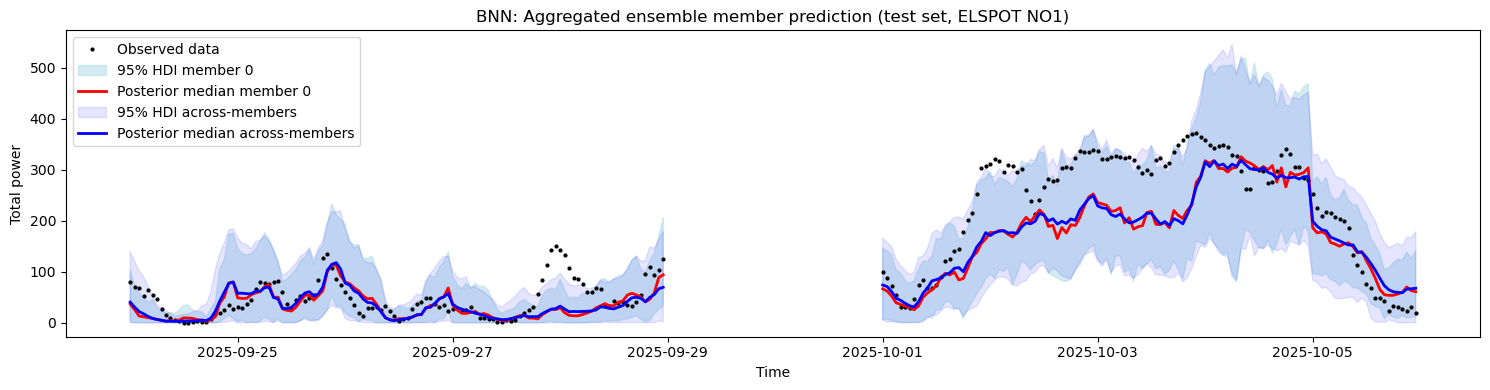

2
Loaded scaler parameters for ELSPOT NO2 and nowcast
  Saved at: 2026-04-07 15:24:08
  Split time: 2025-01-01 00:00:00+01:00
Loading evaluation data for 10 dates in zone ELSPOT NO2...
Loading evaluation data for 2025-09-22 in zone ELSPOT NO2
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-23 in zone ELSPOT NO2
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-24 in zone ELSPOT NO2
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Loading evaluation data for 2025-09-25

/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


Loading evaluation data for 2025-10-03 in zone ELSPOT NO2
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 RangeIndex(start=0, stop=4087, step=1)
Maintenance hours in operational period: 12
Preprocessing done. X_eval shape: (228, 17, 15, 10)
Dropped timestamps due to maintenance: 0
Choose ensemble member 0
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-28_18-30-32_nowcast_ELSPOT_NO2.pkl
Choose ensemble member 1
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-28_18-30-32_nowcast_ELSPOT_NO2.pkl
Choose ensemble member 2
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-28_18-30-32_nowcast_ELSPOT_NO2.pkl
Choose ensemble member 3
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-28_18-30-32_nowcast_ELSPOT_NO2.pkl
Choose ensemble member 4
Loading specified checkpoint: .

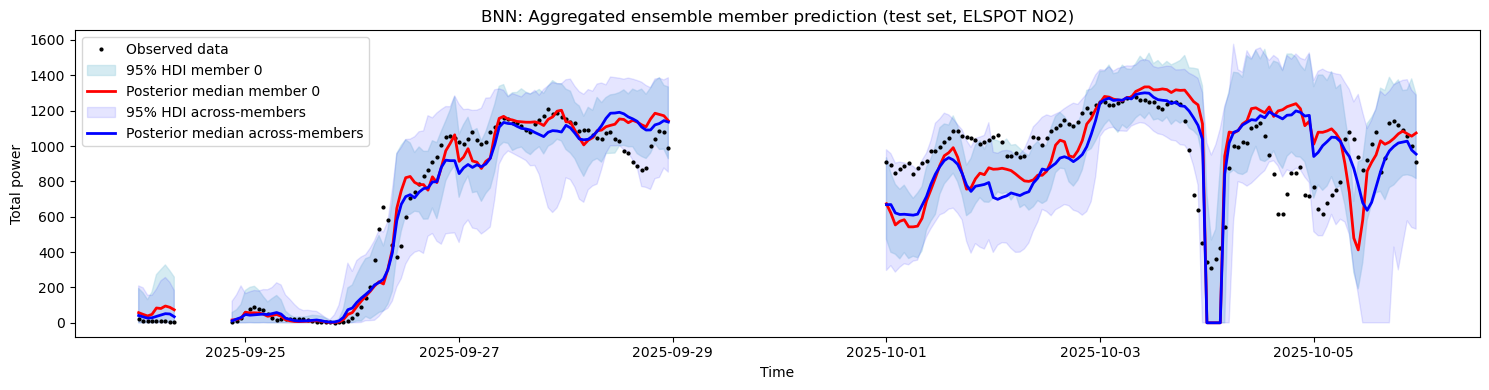

In [118]:
# ------------------------------------------------------------------------
# Change those parameters
model_type = "BNN"
data_split = "test"
dataset = "forecast"
# ------------------------------------------------------------------------

errors = {"rmse": [], "crps": []}

# Iterate over all bidding zones
for i in range(1, 5):
    print(i)
    # ------------------------------------------------------------------------
    # Load data
    # ------------------------------------------------------------------------
    path_to_model_cfg = PATH_MODEL_CFG[model_type](i)
    model_cfg = load_config(path_to_model_cfg)

    file_name = CHECKPOINTS[model_type][f"ELSPOT NO{i}"]

    if data_split == "test":
        scaler_data_nowcast = load_scaler_params(
            bid_zone=f"ELSPOT NO{i}", dataset="nowcast", dir_path="../checkpoints"
        )
        data = load_evaluation_forecast_data(
            dates=evaluation_dates,
            scaler_params=scaler_data_nowcast["scaler_params"],
            site_scaler_params=scaler_data_nowcast["site_scaler_params"],
            bid_zone=f"ELSPOT NO{i}",
            ensemble_members=None,
            variance_feature=False,
        )

    # Training or validation data
    else:
        data_cfg = load_config(model_cfg.data.path)
        if dataset == "forecast":
            data_cfg.dataset = "forecast"
            data_cfg.ensemble = SimpleNamespace(members=None, variance=False)
        data = load_dataset(data_cfg)

    target = data[f"Y_{DATA_SPLIT[data_split]}_gen"]

    # ------------------------------------------------------------------------
    # Evaluate model
    # ------------------------------------------------------------------------
    preds_list = []
    for member in range(15):

        if model_cfg.backend == "numpyro":

            _, _, _, preds = test_BNN(
                file_name, data, member=member, split=DATA_SPLIT[data_split]
            )

        elif model_cfg.backend == "torch":

            _, _, _, preds = test_QR(
                file_name,
                data,
                ensembles=False,
                from_now_to_forecast=True,
                member=member,
                split=DATA_SPLIT[data_split],
            )

        preds_list.append(preds)
        if dataset == "nowcast":
            # No ensemble members
            break

    # ------------------------------------------------------------------------
    # Plot results
    # ------------------------------------------------------------------------
    if dataset == "forecast":
        if model_type == "QRNN":
            plot_qr_prediction_ensemble(
                Y_true=data[f"Y_{DATA_SPLIT[data_split]}_gen"],
                Y_pred=preds_list,
                plot_interval=[0, 1080],
                title=f"{model_type}: Aggregated ensemble member prediction ({data_split} set, {model_cfg.data.bid_zone})",
                timestamps=(
                    data["index"]
                    if data_split == "test"
                    else data[f"X_{DATA_SPLIT[data_split]}_timestamps"]
                ),
            )
            # plt.savefig(
            #     f"../plots/ensemble_{data_cfg.dataset}_{model_type}_{model_cfg.data.bid_zone}_val.pdf"
            # )
            plt.show()
        if model_type == "BNN":
            checkpoint = load_checkpoint(file_name=file_name)
            model = build_model(checkpoint["model_cfg"], data)

            plot_bnn_gamma_combined(
                checkpoint,
                model,
                data,
                data_cfg,
                [0, 1080],
                split=DATA_SPLIT[data_split],
            )
            # plt.savefig(
            #     f"../plots/ensemble_{data_cfg.dataset}_{model_type}_{model_cfg.data.bid_zone}_val.pdf"
            # )
            plt.show()

    if dataset == "nowcast":
        if model_type == "QRNN":

            model, checkpoint = load_torch_model(
                file_name=file_name, quantiles=quantiles
            )
            quantiles = torch.linspace(0, 1, model_cfg.params.num_quantiles)

            _, y_pred, y_pred_train = evaluate_model(model, data, quantiles, model_cfg)

            median, lower, upper = extract_quantile_curves(
                Y_pred_quantiles=y_pred_train if data_split == "train" else y_pred,
                quantiles=quantiles,
                median_q=0.5,
                lower_q=0.025,
                upper_q=0.975,
            )
            percentiles = np.stack([lower, upper], axis=1)
            print(
                data[f"Y_{DATA_SPLIT[data_split]}_gen"].shape,
                percentiles.shape,
                median.shape,
            )
            plot_qr_hdi_prediction_simple(
                Y_true=data[f"Y_{DATA_SPLIT[data_split]}_gen"],
                conf_interval=percentiles,
                medians=median,
                plot_interval=[0, 1080],
                title=f"{model_type}: Nowcast prediction ({data_split} set, {model_cfg.data.bid_zone})",
                timestamps=data[f"X_{DATA_SPLIT[data_split]}_timestamps"],
            )
            # plt.savefig(
            #     f"../plots/{data_cfg.dataset}_{model_type}_{model_cfg.data.bid_zone}_{DATA_SPLIT[data_split]}.pdf"
            # )
            plt.show()

        if model_type == "BNN":
            checkpoint = load_checkpoint(file_name=file_name)
            model = build_model(checkpoint["model_cfg"], data)
            (
                metrics_train,
                y_pred_train,
                predictive_train,
                median_train,
                percentiles_train,
                hdis_train,
            ) = evaluate_numpyro_on_train_set(
                model,
                checkpoint["samples"],
                checkpoint["rng_key_predict"],
                data,
                model_cfg,
                split=DATA_SPLIT[data_split],
            )
            # Plot
            print(
                data[f"Y_{DATA_SPLIT[data_split]}_gen"].shape,
                hdis_train.T.shape,
                median_train.shape,
            )
            plot_qr_hdi_prediction_simple(
                Y_true=data[f"Y_{DATA_SPLIT[data_split]}_gen"],
                conf_interval=hdis_train.T,  # hdi_list[0].T,
                medians=median_train,  # median_list[0],
                plot_interval=[0, 1080],
                title=f"{model_type}: Nowcast prediction ({data_split} set, {model_cfg.data.bid_zone})",
                timestamps=data[f"X_{DATA_SPLIT[data_split]}_timestamps"],
            )
            # plt.savefig(
            #     f"../plots/{data_cfg.dataset}_{model_type}_{model_cfg.data.bid_zone}_train.pdf"
            # )
            plt.show()